# HSA_Cam_B_008.py
This file uses the LHHW_Model of kinetics to determine kinetic parameters and an optimal next experiment.

HSA_Cam_B_004.py is the model. This uses homoscedastic noise and exponential priors.

## First try to actually infer the model

### Plan:
* generate data
* instantiate the model
* infer the model
* check HDIs
* select next experiment at highest HDI

### Results:
* Inference works
* HDIs work
* max HDI strategy does work better now 
* the priors are not updated significantly, which is really bad
* use exponential priors for the kinetic parameters
* next step: implement relative HDI

In [1]:
import pytensor

pytensor.config.mode = "JAX"

import jax.numpy as jnp
import jax
import numpy as np
import matplotlib.pyplot as plt

import pymc as pm

import arviz as az
from scipy.optimize import minimize

import sys

sys.argv = [""]

In [2]:
from HSA_Cam_B_012 import (
    SIDX,
    TRUE_PARAMS,
    _kinetics_model,
    input_p,
    bmodel,
    observe_at_proposal,
    mp_KL_divergence,
)

In [3]:
def post_model_over_T(proposal, idata, key="posterior"):

    test_params = {
        "p_i": input_p(
            jnp.array(proposal[1]).reshape(1, 1),
            jnp.array(proposal[2]).reshape(1, 1),
            jnp.array(proposal[3]).reshape(1, 1),
            jnp.array(proposal[4]).reshape(1, 1),
        ).reshape(1, -1),
        "T": jnp.linspace(500.0, 600.0, 100).reshape(-1, 1),
        "k0": idata[key]["k0"].values.reshape(1, -1),
        "Ea_k": idata[key]["Ea_k"].values.reshape(1, -1),
        "A_oh": idata[key]["A_oh"].values.reshape(1, -1),
        "dH_oh": idata[key]["dH_oh"].values.reshape(1, -1),
        "A_h2": idata[key]["A_h2"].values.reshape(1, -1),
        "dH_h2": idata[key]["dH_h2"].values.reshape(1, -1),
        "A_mix": idata[key]["A_mix"].values.reshape(1, -1),
        "dH_mix": idata[key]["dH_mix"].values.reshape(1, -1),
    }

    test_res = _kinetics_model(**test_params)
    return test_res


def true_model_over_T(proposal):
    true_res_T = _kinetics_model(
        input_p(
            jnp.array(proposal[1]).reshape(1, 1),
            jnp.array(proposal[2]).reshape(1, 1),
            jnp.array(proposal[3]).reshape(1, 1),
            jnp.array(proposal[4]).reshape(1, 1),
        ).reshape(1, -1),
        jnp.linspace(500.0, 600.0, 100).reshape(-1, 1),
        *TRUE_PARAMS.values(),
    )
    return true_res_T

In [4]:
def plot_post_model_at_proposal(proposal, test_res, true_res, Ts):
    plt.plot(
        Ts,
        test_res.mean(axis=1),
    )
    plt.plot(
        Ts,
        true_res.squeeze(),
        color="black",
        linestyle="--",
    )
    plt.fill_between(
        x=Ts,
        y1=np.percentile(test_res, 2.5, axis=1),
        y2=np.percentile(test_res, 97.5, axis=1),
        alpha=0.3,
        zorder=0,
    )
    ax = plt.gca()
    ax.text(
        0.05,
        0.95,
        f"pred. @ p={proposal[1]:.2f}, F= {proposal[2]:.2f}, C= {proposal[3]:.2f}, H2= {proposal[4]:.2f}",
        transform=ax.transAxes,
        fontsize=10,
    )
    ax2 = ax.twinx()
    ax2.plot(
        Ts,
        np.percentile(test_res, 97.5, axis=1) - np.percentile(test_res, 2.5, axis=1),
        color="orange",
    )

In [5]:
T = jnp.array([560, 570, 580], dtype=jnp.float32).reshape(-1, 1)
p = jnp.array([4, 5, 6], dtype=jnp.float32).reshape(-1, 1)
c2h = jnp.array([1], dtype=jnp.float32).reshape(-1, 1)
f = jnp.array([1000], dtype=jnp.float32).reshape(-1, 1)
c2i = jnp.array([0.5], dtype=jnp.float32).reshape(-1, 1)

p_i = input_p(p, c2h, f, c2i)
print(p_i)

r = _kinetics_model(p_i, T, *TRUE_PARAMS.values())
print(r)
r_obs = r + jax.random.normal(jax.random.PRNGKey(1), r.shape) * 1e-5
print(r_obs)

[[9.99750078e-01 9.99750078e-01 0.00000000e+00 9.99750078e-04
  1.99950016e+00]
 [1.24968760e+00 1.24968760e+00 0.00000000e+00 1.24968760e-03
  2.49937519e+00]
 [1.49962512e+00 1.49962512e+00 0.00000000e+00 1.49962512e-03
  2.99925023e+00]]
[[7.61192633e-05]
 [1.16399861e-04]
 [1.72598760e-04]]
[[8.56923350e-05]
 [1.06700571e-04]
 [1.82669424e-04]]


In [6]:
def max_func(x, idata, key="posterior"):
    T = x[0].reshape(1, 1)
    p = x[1].reshape(1, 1)
    c2h = x[2].reshape(1, 1)
    f = x[3].reshape(1, 1)
    c2i = x[4].reshape(1, 1)
    p_i = input_p(p, c2h, f, c2i)
    res = _kinetics_model(
        p_i,
        T,
        idata[key]["k0"].values.reshape(1, -1),
        idata[key]["Ea_k"].values.reshape(1, -1),
        idata[key]["A_oh"].values.reshape(1, -1),
        idata[key]["dH_oh"].values.reshape(1, -1),
        idata[key]["A_h2"].values.reshape(1, -1),
        idata[key]["dH_h2"].values.reshape(1, -1),
        idata[key]["A_mix"].values.reshape(1, -1),
        idata[key]["dH_mix"].values.reshape(1, -1),
    )
    HDI = jnp.percentile(res, 97.5) - jnp.percentile(res, 2.5)
    return -HDI

In [7]:
model = bmodel(
    (
        np.asarray(T),
        np.asarray(p),
        np.asarray(c2h),
        np.asarray(f),
        np.asarray(c2i),
    ),
    np.asarray(r_obs),
)

In [8]:
with model:
    prior_idata = pm.sample_prior_predictive(samples=1000)

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\pytensor\link\jax\linker.py:32: UserWarning: The RandomType SharedVariables [RNG(<Generator(PCG64) at 0x1863FDA0E40>), RNG(<Generator(PCG64) at 0x1863FDA1380>), RNG(<Generator(PCG64) at 0x1863FDA0040>), RNG(<Generator(PCG64) at 0x1863FDA0200>), RNG(<Generator(PCG64) at 0x1863FDA0BA0>), RNG(<Generator(PCG64) at 0x186410A1000>), RNG(<Generator(PCG64) at 0x1863FDA09E0>), RNG(<Generator(PCG64) at 0x1863FDA1000>), RNG(<Generator(PCG64) at 0x1863FDA12A0>), RNG(<Generator(PCG64) at 0x1863FDA0F20>)] will not be used in the compiled JAX graph. Instead a copy will be used.
  warnings.warn(
Sampling: [A_h2, A_mix, A_oh, Ea_k, LH2, dH_h2, dH_mix, dH_oh, k0, sigma_r]


generate the first 4 points on purpose

In [9]:
proposals = np.array(
    [
        [500.0, 4.0, 0.5, 1000.0, 0.5],
        [600.0, 4.0, 0.5, 1000.0, 0.5],
        [500.0, 20.0, 0.5, 1000.0, 0.5],
        [600.0, 20.0, 0.5, 1000.0, 0.5],
    ]
)

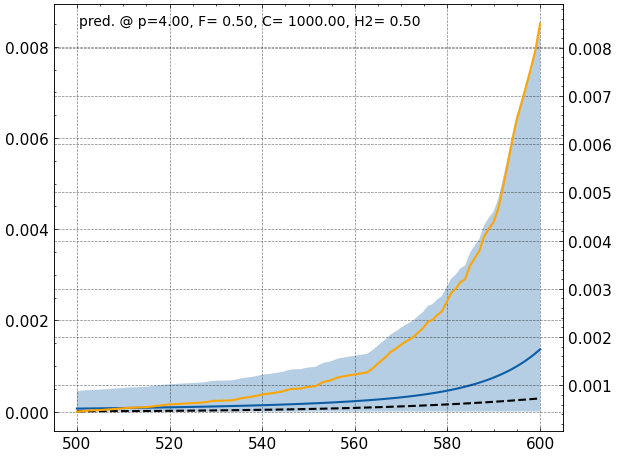

In [10]:
Ts = jnp.linspace(500, 600, 100)
test_res = post_model_over_T(proposals[0], prior_idata, key="prior")
true_res = true_model_over_T(proposals[0])
plot_post_model_at_proposal(proposals[0], test_res, true_res, Ts)

### The ax optimization

In [11]:
from ax import Client, RangeParameterConfig

client = Client()

parameters = [
    RangeParameterConfig(name="T", parameter_type="float", bounds=(500.0, 600.0)),
    RangeParameterConfig(name="p", parameter_type="float", bounds=(4.0, 20.0)),
    RangeParameterConfig(name="c2h", parameter_type="float", bounds=(0.1, 5.0)),
    RangeParameterConfig(name="f", parameter_type="float", bounds=(500.0, 2000.0)),
    RangeParameterConfig(name="c2i", parameter_type="float", bounds=(0.0, 1.0)),
]

client.configure_experiment(
    parameters=parameters,
)
client.configure_optimization(objective="KLD")

## Automatic Iteration

In [12]:
n_iterations = 8
i_datas = []
max_KLDs = []

In [ ]:
for i in range(n_iterations):
    print(f"Iteration {i+1}/{n_iterations}")
    T, p, c2h, f, c2i, r_obs = observe_at_proposal(proposals)
    model = bmodel(
        (
            np.asarray(T),
            np.asarray(p),
            np.asarray(c2h),
            np.asarray(f),
            np.asarray(c2i),
        ),
        np.asarray(r_obs),
    )
    with model:
        idata = pm.sample(
            tune=100,
            draws=400,
            chains=4,
            target_accept=0.9,
            return_inferencedata=True,
        )
        i_datas.append(idata)

    for _ in range(10):
        trials = client.get_next_trials(max_trials=1)
        for trial_idx, parameters in trials.items():
            candidate = jnp.array(
                [
                    parameters["T"],
                    parameters["p"],
                    parameters["c2h"],
                    parameters["f"],
                    parameters["c2i"],
                ]
            )
            KLD_vals = mp_KL_divergence(
                proposals,
                r_obs,
                candidate.squeeze(),
                idata,
                n_hyp_samples=4,
            )
            mean_KLD = KLD_vals.sum(axis=1).mean(axis=0).item()
            std_KLD = KLD_vals.sum(axis=1).std(axis=0).item()
            client.complete_trial(
                trial_index=trial_idx,
                raw_data={"KLD": (mean_KLD, std_KLD)},
            )

    best_parameters, expected_KLD, index, name = client.get_best_parameterization()
    proposal = jnp.array(
        [
            best_parameters["T"],
            best_parameters["p"],
            best_parameters["c2h"],
            best_parameters["f"],
            best_parameters["c2i"],
        ]
    )
    max_KLDs.append(expected_KLD["KLD"][0])
    proposals = np.append(proposals, np.atleast_2d(proposal), axis=0)
    print("Next Proposal:\n", proposal)

Iteration 1/8


Initializing NUTS using jitter+adapt_diag...
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\pytensor\link\c\cmodule.py:2968: UserWarning:

PyTensor could not link to a BLAS installation. Operations that might benefit from BLAS will be severely degraded.
This usually happens when PyTensor is installed via pip. We recommend it be installed via conda/mamba/pixi instead.
Alternatively, you can use an experimental backend such as Numba or JAX that perform their own BLAS optimizations, by setting `pytensor.config.mode == 'NUMBA'` or passing `mode='NUMBA'` when compiling a PyTensor function.
For more options and details see https://pytensor.readthedocs.io/en/latest/troubleshooting.html#how-do-i-configure-test-my-blas-library

Multiprocess sampling (4 chains in 4 jobs)
NUTS: [k0, Ea_k, A_oh, dH_oh, A_h2, dH_h2, A_mix, dH_mix, sigma_r]


Output()

Sampling 4 chains for 100 tune and 400 draw iterations (400 + 1_600 draws total) took 99 seconds.
There were 281 divergences after tuning. Increase `target_accept` or reparameterize.
Chain 0 reached the maximum tree depth. Increase `max_treedepth`, increase `target_accept` or reparameterize.
Chain 1 reached the maximum tree depth. Increase `max_treedepth`, increase `target_accept` or reparameterize.
Chain 2 reached the maximum tree depth. Increase `max_treedepth`, increase `target_accept` or reparameterize.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details
[INFO 10-22 09:45:09] ax.api.client: GenerationStrategy(name='Center+Sobol+MBM:fast', nodes=[CenterGenerationNode(next_node_name='Sobol'), Genera

Generated 4 hypothetical observations at new condition


In [ ]:
print(mean_KLD.item())

97.75109440050859


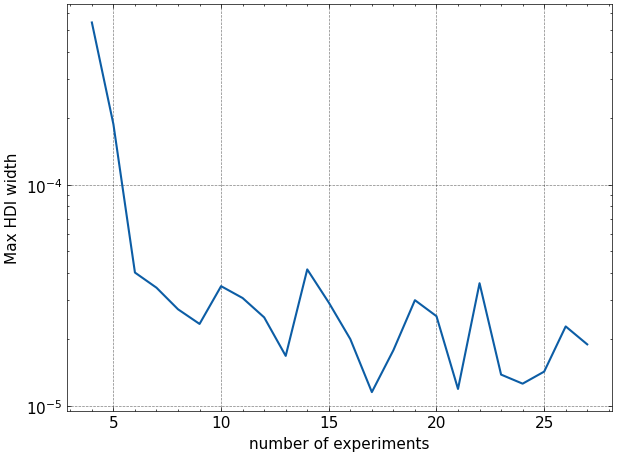

In [ ]:
plt.plot(np.arange(len(max_HDIs)) + 4, max_HDIs)
plt.xlabel("number of experiments")
plt.ylabel("Max HDI width")
plt.yscale("log")
plt.show()

In [ ]:
for i, idata in enumerate(i_datas):
    if i == 0:
        idata.prior = prior_idata.prior
    else:
        idata.prior = i_datas[i - 1].posterior

array([[<Axes: >, <Axes: >, <Axes: xlabel='k0'>]], dtype=object)

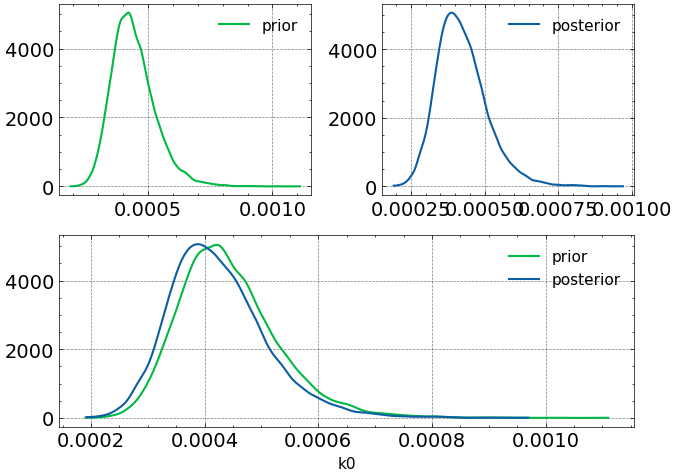

In [ ]:
import ICIW_Plots

plt.style.use("ICIWstyle")
az.plot_dist_comparison(i_datas[8], var_names=["k0"], figsize=(7, 5))

array([[<Axes: title={'center': 'dH_h2'}>,
        <Axes: title={'center': 'dH_h2'}>],
       [<Axes: title={'center': 'dH_mix'}>,
        <Axes: title={'center': 'dH_mix'}>],
       [<Axes: title={'center': 'k0'}>, <Axes: title={'center': 'k0'}>],
       [<Axes: title={'center': 'Ea_k'}>,
        <Axes: title={'center': 'Ea_k'}>],
       [<Axes: title={'center': 'A_oh'}>,
        <Axes: title={'center': 'A_oh'}>],
       [<Axes: title={'center': 'dH_oh'}>,
        <Axes: title={'center': 'dH_oh'}>],
       [<Axes: title={'center': 'A_h2'}>,
        <Axes: title={'center': 'A_h2'}>],
       [<Axes: title={'center': 'A_mix'}>,
        <Axes: title={'center': 'A_mix'}>],
       [<Axes: title={'center': 'sigma_r'}>,
        <Axes: title={'center': 'sigma_r'}>],
       [<Axes: title={'center': 'y_hat'}>,
        <Axes: title={'center': 'y_hat'}>]], dtype=object)

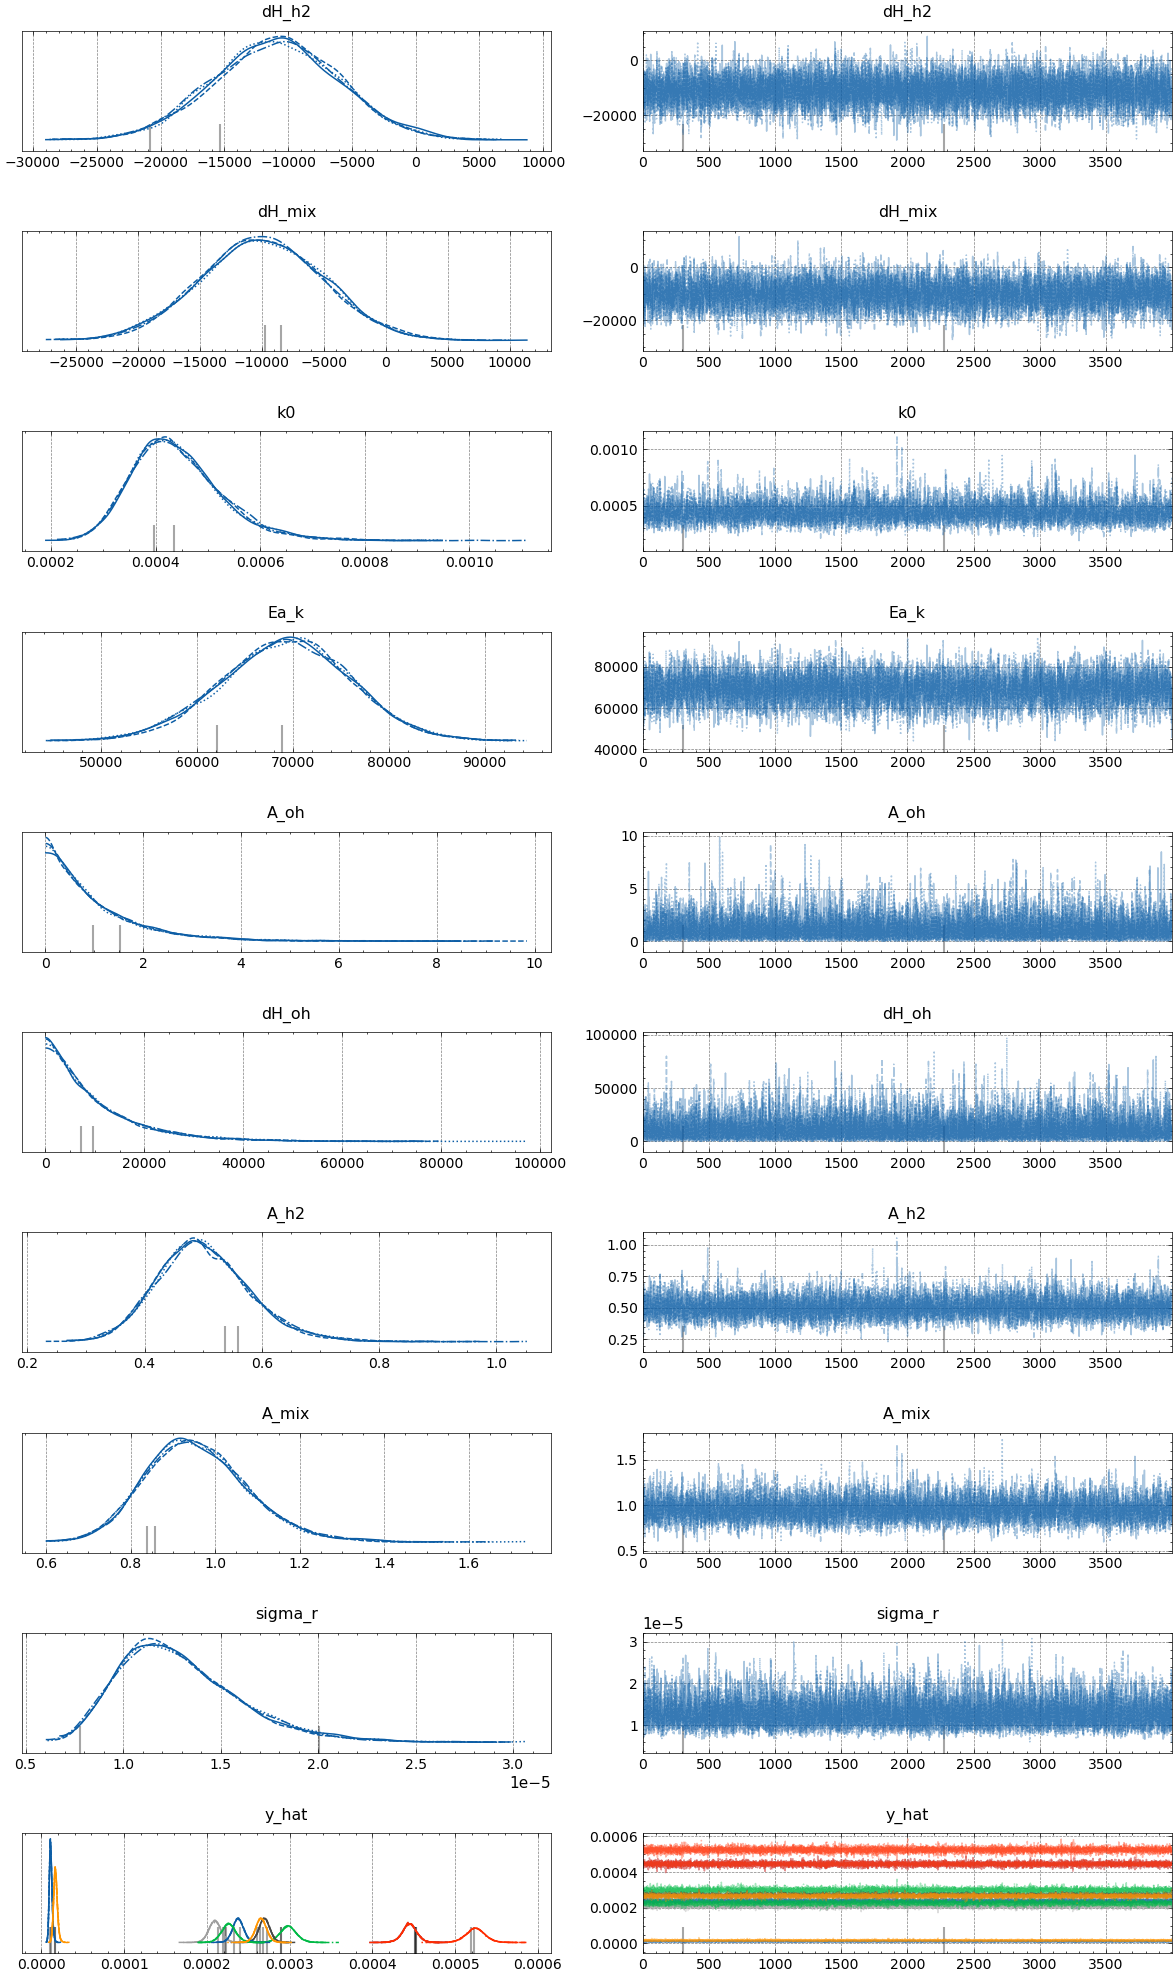

In [ ]:
az.plot_trace(i_datas[-1])

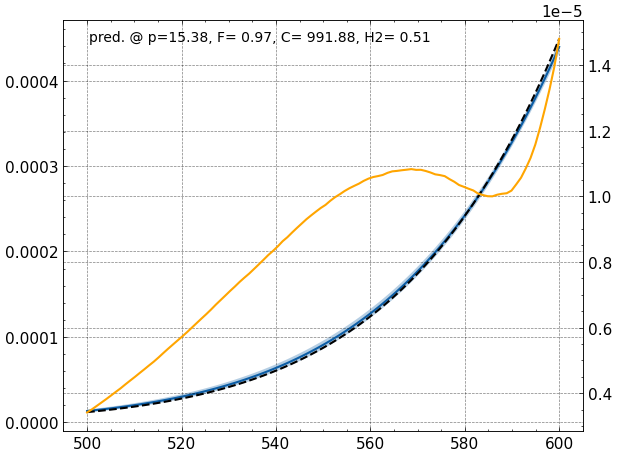

In [ ]:
i = 24
# test_res = post_model_over_T(proposals[i], prior_idata, key="prior")
test_res = post_model_over_T(proposals[i], i_datas[-1], key="posterior")
true_res_T = true_model_over_T(proposals[i])
plot_post_model_at_proposal(proposals[i], test_res, true_res_T, Ts)

In [ ]:
display(pm.summary(idata, hdi_prob=0.95))

,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
dH_h2,-10607.228,4734.047,-19826.259,-1285.301,54.469,36.967,7541.0,9461.0,1.0
dH_mix,-10453.655,4789.833,-19920.226,-1160.746,58.446,40.302,6725.0,8966.0,1.0
k0,0.000,0.000,0.000,0.000,0.000,0.000,5532.0,7323.0,1.0
Ea_k,71632.479,5589.890,60498.304,82358.843,75.010,50.485,5555.0,8020.0,1.0
A_oh,0.993,0.996,0.000,2.985,0.009,0.013,7049.0,5674.0,1.0
dH_oh,10049.469,10143.770,1.297,30313.782,77.061,134.572,10770.0,6960.0,1.0
A_h2,0.457,0.045,0.371,0.543,0.001,0.000,6839.0,8742.0,1.0
A_mix,0.845,0.078,0.697,1.005,0.001,0.001,6371.0,8637.0,1.0
sigma_r,0.000,0.000,0.000,0.000,0.000,0.000,9070.0,8640.0,1.0
"y_hat[0, 0]",0.000,0.000,0.000,0.000,0.000,0.000,8919.0,10609.0,1.0


### Generate the exploration pattern

C:\Users\hanne\AppData\Local\Temp\ipykernel_21860\2035428282.py:81: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


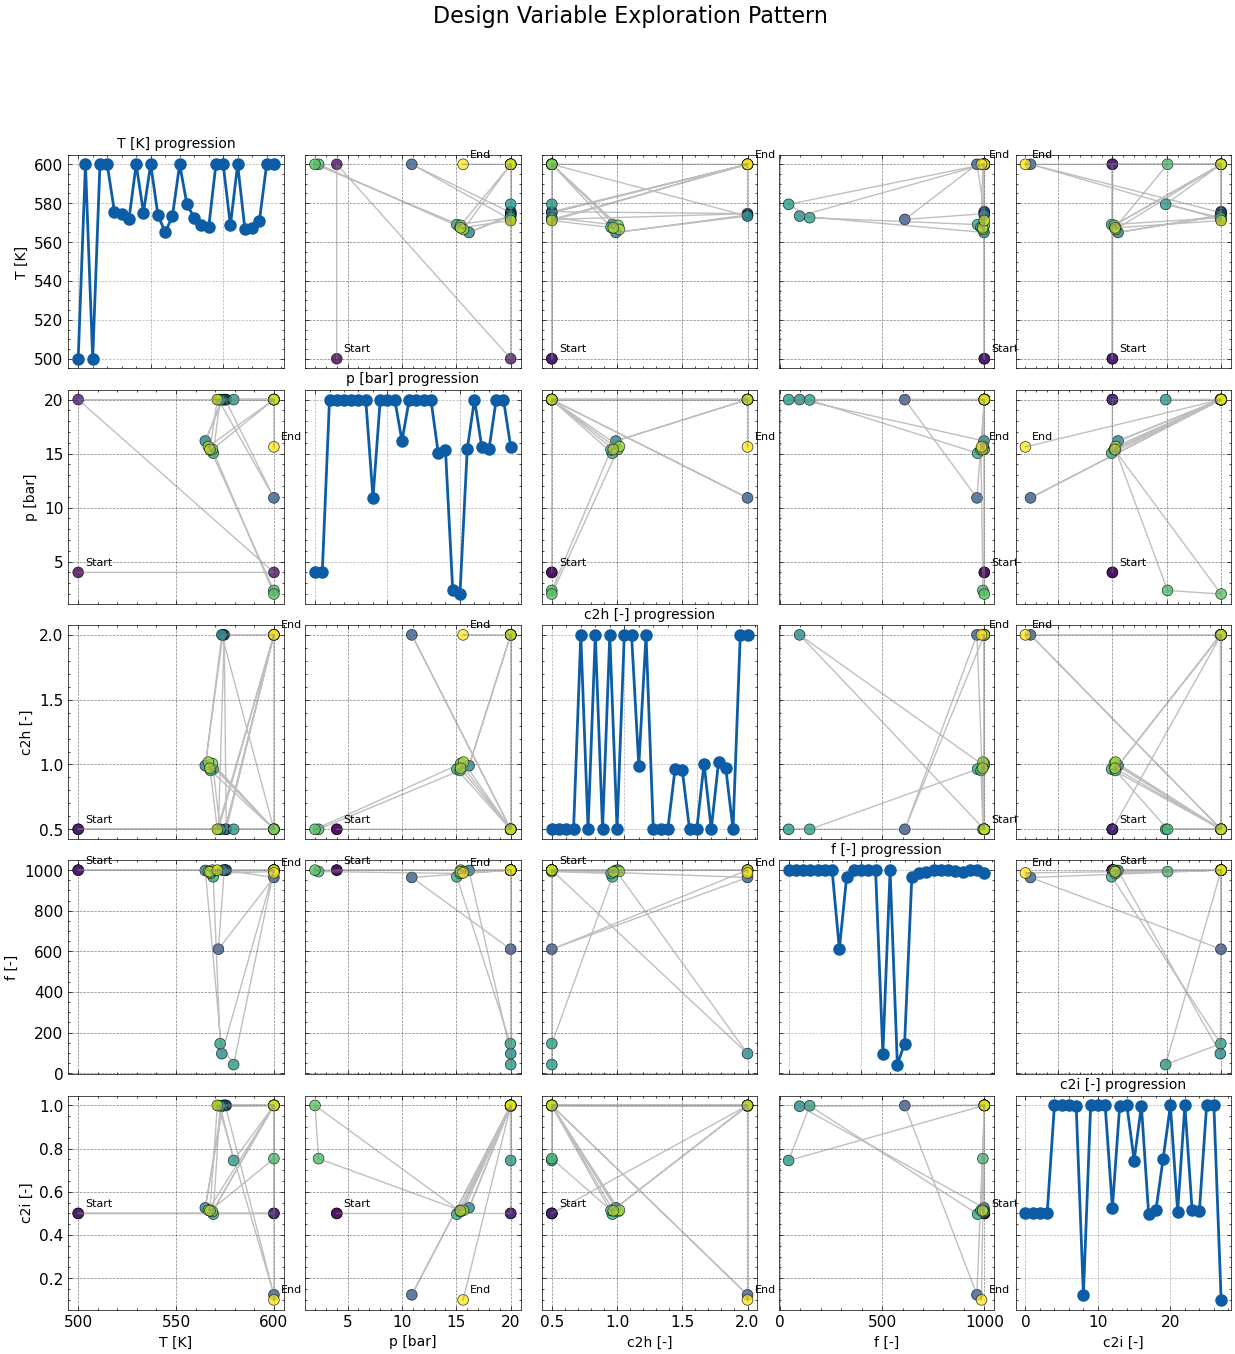

In [ ]:
# create a 5x5 matrix plot with no gaps between the subplots
fig, axs = plt.subplots(
    5,
    5,
    figsize=(15, 15),
    sharex=False,
    sharey=False,
    gridspec_kw={"hspace": 0.1, "wspace": 0.1},
)

# Variable names for labeling
var_names = ["T [K]", "p [bar]", "c2h [-]", "f [-]", "c2i [-]"]

# Assuming proposals array exists with shape (n_experiments, 5)
n_experiments = proposals.shape[0]
experiment_order = np.arange(n_experiments)

for i in range(5):
    for j in range(5):
        ax = axs[i, j]

        if i == j:  # Diagonal: time series of each variable
            ax.plot(experiment_order, proposals[:, i], "o-", linewidth=2, markersize=8)
            ax.set_title(f"{var_names[i]} progression", fontsize=10, pad=5)
            ax.grid(True, alpha=0.3)
            if i == 4:  # Bottom row
                ax.set_xlabel("Experiment #")
        else:  # Off-diagonal: scatter plots
            # Color points by experiment order for temporal information
            scatter = ax.scatter(
                proposals[:, j],
                proposals[:, i],
                c=experiment_order,
                cmap="viridis",
                s=60,
                alpha=0.8,
                edgecolors="black",
                linewidth=0.5,
            )

            # Add trajectory lines
            ax.plot(
                proposals[:, j],
                proposals[:, i],
                "-",
                alpha=0.5,
                color="gray",
                linewidth=1,
            )

            # Label first and last points
            ax.annotate(
                "Start",
                (proposals[0, j], proposals[0, i]),
                xytext=(5, 5),
                textcoords="offset points",
                fontsize=8,
            )
            if n_experiments > 1:
                ax.annotate(
                    "End",
                    (proposals[-1, j], proposals[-1, i]),
                    xytext=(5, 5),
                    textcoords="offset points",
                    fontsize=8,
                )

        # Set labels only on edges
        if i == 4:  # Bottom row
            ax.set_xlabel(var_names[j], fontsize=10)
        if j == 0:  # Left column
            ax.set_ylabel(var_names[i], fontsize=10)

        # Remove tick labels for inner plots
        if i < 4:
            ax.set_xticklabels([])
        if j > 0:
            ax.set_yticklabels([])

plt.suptitle("Design Variable Exploration Pattern", fontsize=16, y=0.98)
plt.tight_layout()
plt.show()

## Quantify the information gain

In [ ]:
import xarray

info_gains = []
for i in range(24):
    klds = kl_divergence_between_models(
        idata_new=i_datas[i],
        idata_old=i_datas[i - 1] if i > 0 else i_datas[0],
        key_new="posterior",
        key_old="posterior" if i > 0 else "prior",
        n_samples=5,
        var_names=[
            "k0",
            "Ea_k",
            "A_oh",
            "dH_oh",
            "A_h2",
            "dH_h2",
            "A_mix",
            "dH_mix",
        ],
    )
    info_gains.append(klds)
kldses = []
for i, klds in enumerate(info_gains):
    print(klds)
    print(klds.sum())
    kldses.append(klds.sum())

[ 1.98294845  0.66202831 -0.09736283  0.05828474  0.3601705   0.52328024
  0.67350231  0.68138525]
4.844236987846095
[0.81767363 0.62706226 3.13501286 0.1085738  1.702683   0.22848792
 0.99785023 0.14421665]
7.761560356692031
[1.09551137 1.19732603 0.32588841 0.12909423 0.22437142 0.22583281
 0.50913616 0.69169761]
4.398858048235379
[ 1.97170001e+01 -2.08412203e-02  6.38046128e-02  1.09514503e-01
  1.93158312e+01  7.68324287e-03  2.17582677e+00 -9.74092744e-02]
41.27140991895812
[1.07841839 0.17287213 2.14329569 0.15127377 1.15490018 0.01871084
 0.44486586 0.03977401]
5.204110872394836
[0.58126512 0.08378746 0.66398187 0.85272552 1.82180673 0.12613821
 0.02200051 0.34630911]
4.498014522290445
[2.48302251 0.42595161 0.10885284 0.71171328 2.22810839 0.11679202
 0.3204495  0.52298615]
6.917876286211694
[ 8.41871112  0.97515324  0.24531787  0.41101725  0.11083959  0.83645512
  3.496402   -0.13097249]
14.362923692715217
[ 0.02277399  0.0059485   0.07293325  0.4619752   0.2243712  -0.0312496

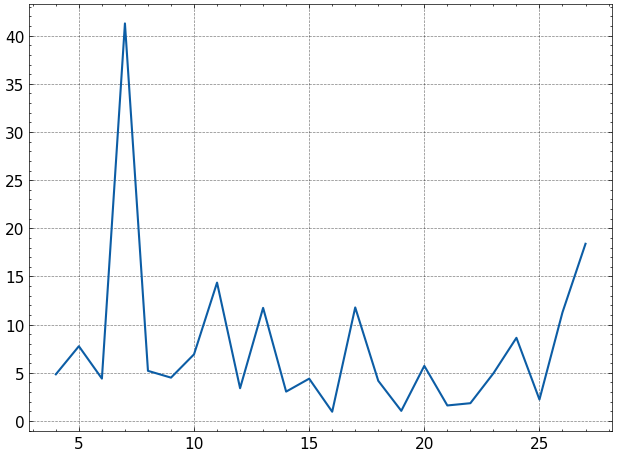

In [ ]:
plt.plot(np.arange(len(kldses)) + 4, kldses)